#INSTALL REQUIRED PACKAGES

In [5]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)
from datasets import Dataset


#HYPERPARAMETER & EXPERIMENT CONFIGURATION

In [6]:
LEARNING_RATE = 2e-5      # Options: 1e-5, 2e-5, 3e-5, 5e-5
NUM_EPOCHS = 3           # Options: 2, 3, 4, 5
BATCH_SIZE = 16          # Options: 8, 16
MAX_LENGTH = 512         # BERT maximum token limit
USE_CLASS_WEIGHTS = True # True = Class-Weighted Cross-Entropy, False = Standard Cross-Entropy
RANDOM_STATE = 42

print(f"Configuration:")
print(f"  Learning Rate:    {LEARNING_RATE}")
print(f"  Epochs:           {NUM_EPOCHS}")
print(f"  Batch Size:       {BATCH_SIZE}")
print(f"  Max Length:       {MAX_LENGTH}")
print(f"  Class Weights:    {USE_CLASS_WEIGHTS}")

Configuration:
  Learning Rate:    2e-05
  Epochs:           3
  Batch Size:       16
  Max Length:       512
  Class Weights:    True


#CLINICAL NOTE PRESERVATION & CHUNKING SUPPORT

In [7]:
def head_tail_truncate(text, max_words=380, head_ratio=0.5):
    """
    Preserves Chief Complaint/History at start (head) and Impression/Plan at end (tail)
    within BERT's 512 subword token budget.
    """
    if not isinstance(text, str):
        return ""
    words = text.split()
    if len(words) <= max_words:
        return text
    head_len = int(max_words * head_ratio)
    tail_len = max_words - head_len
    return " ".join(words[:head_len]) + " " + " ".join(words[-tail_len:])


class ClinicalDocumentChunker:
    """
    Code support for multi-chunk document representation experiments (Part 14).
    Splits long transcriptions into overlapping sliding windows (e.g., 256 tokens, stride 128).
    """
    def __init__(self, chunk_size=256, chunk_stride=128):
        self.chunk_size = chunk_size
        self.chunk_stride = chunk_stride

    def chunk_text(self, text):
        words = text.split()
        if len(words) <= self.chunk_size:
            return [text]
        chunks = []
        for i in range(0, len(words), self.chunk_stride):
            chunk = " ".join(words[i:i + self.chunk_size])
            chunks.append(chunk)
            if i + self.chunk_size >= len(words):
                break
        return chunks


def profile_transcription_lengths(texts, token_limits=[256, 384, 512]):
    """Calculates document word/token distribution and percentages exceeding limits."""
    n_docs = len(texts)
    word_counts = [len(str(t).split()) for t in texts]
    approx_tokens = [int(w * 1.3) for w in word_counts]
    print("\n--- TRANSCRIPTION LENGTH & TOKEN BUDGET PROFILING ---")
    print(f"Total documents:   {n_docs}")
    print(f"Min words:         {np.min(word_counts)}")
    print(f"Mean words:        {np.mean(word_counts):.1f}")
    print(f"Median words:      {np.median(word_counts):.1f}")
    print(f"Max words:         {np.max(word_counts)}")
    for lim in token_limits:
        cnt = sum(1 for t in approx_tokens if t > lim)
        print(f"Docs exceeding {lim} tokens: {cnt} ({cnt/n_docs*100:.1f}%)")

#LOAD SPLITS & RUN PART 19 ZERO-LEAKAGE VERIFICATION

In [9]:
train_path = "train_data.csv"
val_path = "validation_data.csv"
test_path = "test_data.csv"

# In Colab, prompt upload if files are missing in current directory
for p in [train_path, val_path, test_path]:
    if not os.path.exists(p):
        print(f"Please upload '{p}' from your local onecall_model2/models/ folder:")
        try:
            from google.colab import files
            uploaded = files.upload()
        except ImportError:
            pass

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

# Strict Data Quality Verification (Part 19)
train_texts = set(train_df['transcription'].dropna())
val_texts = set(val_df['transcription'].dropna())
test_texts = set(test_df['transcription'].dropna())

dup_train_test = len(train_texts.intersection(test_texts))
dup_train_val = len(train_texts.intersection(val_texts))
dup_val_test = len(val_texts.intersection(test_texts))

print("\n" + "=" * 65)
print("DATA QUALITY VERIFICATION REPORT (PRE-TRAINING)")
print("=" * 65)
print(f"Train samples:                    {len(train_df)}")
print(f"Validation samples:               {len(val_df)}")
print(f"Test samples:                     {len(test_df)}")
print("-" * 65)
print(f"Duplicate train/test texts:       {dup_train_test} (Expected: 0)")
print(f"Duplicate train/validation texts: {dup_train_val} (Expected: 0)")
print(f"Duplicate validation/test texts:  {dup_val_test} (Expected: 0)")
print("=" * 65)

if dup_train_test != 0 or dup_train_val != 0 or dup_val_test != 0:
    raise ValueError("LEAKAGE DETECTED! Overlapping samples between splits. Stopping immediately.")

# Profile document lengths
profile_transcription_lengths(train_df['transcription'].tolist())

Please upload 'train_data.csv' from your local onecall_model2/models/ folder:


Saving train_data.csv to train_data.csv

DATA QUALITY VERIFICATION REPORT (PRE-TRAINING)
Train samples:                    154
Validation samples:               25
Test samples:                     29
-----------------------------------------------------------------
Duplicate train/test texts:       0 (Expected: 0)
Duplicate train/validation texts: 0 (Expected: 0)
Duplicate validation/test texts:  0 (Expected: 0)

--- TRANSCRIPTION LENGTH & TOKEN BUDGET PROFILING ---
Total documents:   154
Min words:         7
Mean words:        365.6
Median words:      256.5
Max words:         1922
Docs exceeding 256 tokens: 99 (64.3%)
Docs exceeding 384 tokens: 70 (45.5%)
Docs exceeding 512 tokens: 44 (28.6%)


#PREPROCESS DATASETS & LABEL ENCODING

In [10]:
print("\nApplying head-tail preservation strategy (380 words)...")
X_train = [head_tail_truncate(t, max_words=380) for t in train_df['transcription'].fillna("")]
X_val = [head_tail_truncate(t, max_words=380) for t in val_df['transcription'].fillna("")]
X_test = [head_tail_truncate(t, max_words=380) for t in test_df['transcription'].fillna("")]

all_classes = sorted(list(set(train_df['medical_specialty']).union(set(val_df['medical_specialty'])).union(set(test_df['medical_specialty']))))
class_to_id = {c: i for i, c in enumerate(all_classes)}
id_to_class = {i: c for i, c in enumerate(all_classes)}

y_train_ids = [class_to_id[c] for c in train_df['medical_specialty']]
y_val_ids = [class_to_id[c] for c in val_df['medical_specialty']]
y_test_ids = [class_to_id[c] for c in test_df['medical_specialty']]

model_name = "emilyalsentzer/Bio_ClinicalBERT"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Loading {model_name} on device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(all_classes),
    id2label=id_to_class,
    label2id=class_to_id
).to(device)

train_dataset = Dataset.from_dict({"text": X_train, "label": y_train_ids})
val_dataset = Dataset.from_dict({"text": X_val, "label": y_val_ids})
test_dataset = Dataset.from_dict({"text": X_test, "label": y_test_ids})

def tokenize_fn(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=MAX_LENGTH)

print("Tokenizing datasets...")
train_tok = train_dataset.map(tokenize_fn, batched=True)
val_tok = val_dataset.map(tokenize_fn, batched=True)
test_tok = test_dataset.map(tokenize_fn, batched=True)


Applying head-tail preservation strategy (380 words)...
Loading emilyalsentzer/Bio_ClinicalBERT on device: cuda (Tesla T4)...


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Tokenizing datasets...


Map:   0%|          | 0/154 [00:00<?, ? examples/s]

Map:   0%|          | 0/25 [00:00<?, ? examples/s]

Map:   0%|          | 0/29 [00:00<?, ? examples/s]

#COMPUTE CLASS WEIGHTS (STRICTLY FROM TRAIN SET)

In [11]:
train_classes_present = np.unique(y_train_ids)
full_weights = np.ones(len(all_classes), dtype=np.float32)
computed_weights = compute_class_weight('balanced', classes=train_classes_present, y=y_train_ids)
for c_id, w in zip(train_classes_present, computed_weights):
    full_weights[c_id] = w
class_weights_tensor = torch.tensor(full_weights, dtype=torch.float).to(device)

class ConfigurableTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        if USE_CLASS_WEIGHTS:
            loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        else:
            loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)
    }

#TRAIN MODEL WITH EARLY STOPPING ON VALIDATION MACRO F1

In [12]:
training_args = TrainingArguments(
    output_dir="./transformer_checkpoints",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=10,
    fp16=torch.cuda.is_available()
)

trainer = ConfigurableTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

print(f"\nStarting Bio_ClinicalBERT fine-tuning ({NUM_EPOCHS} epochs, lr={LEARNING_RATE}, class_weights={USE_CLASS_WEIGHTS})...")
trainer.train()



Starting Bio_ClinicalBERT fine-tuning (3 epochs, lr=2e-05, class_weights=True)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,3.445484,3.349956,0.080000,0.028219
2,3.391818,3.358414,0.040000,0.006173
3,3.257239,3.324374,0.080000,0.020282


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=30, training_loss=3.364846928914388, metrics={'train_runtime': 46.5887, 'train_samples_per_second': 9.917, 'train_steps_per_second': 0.644, 'total_flos': 121586775754752.0, 'train_loss': 3.364846928914388, 'epoch': 3.0})

#

#EVALUATION ON TEST SET


Evaluating winning checkpoint on unseen test set...



MODEL D: BIO_CLINICALBERT EVALUATION RESULTS (TEST SET)
Accuracy:           0.0690
Macro Precision:    0.0193
Macro Recall:       0.0909
Macro F1 (Primary): 0.0303
Weighted Precision: 0.0146
Weighted Recall:    0.0690
Weighted F1:        0.0230


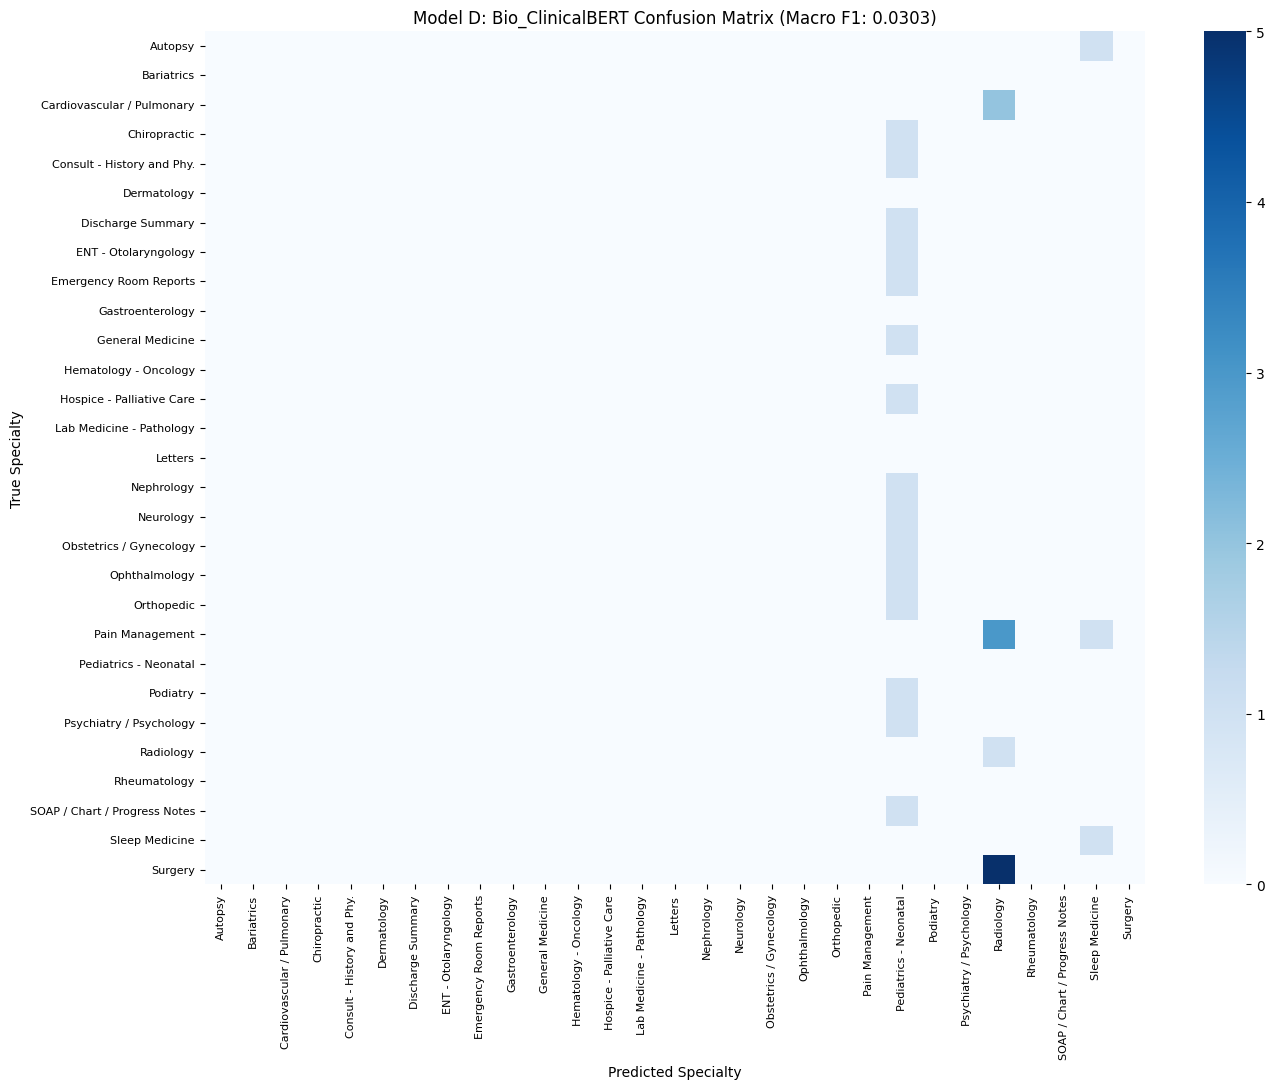


--- EXACT ROW FOR model_comparison.csv ---
Model D: Bio_ClinicalBERT,"Contextual Embeddings (Bio_ClinicalBERT, weighted loss)",0.0690,0.0193,0.0909,0.0303,0.0146,0.0690,0.0230


In [13]:
print("\nEvaluating winning checkpoint on unseen test set...")
preds_output = trainer.predict(test_tok)
y_pred_ids = np.argmax(preds_output.predictions, axis=1)
y_test_pred = [id_to_class[p] for p in y_pred_ids]
y_test_true = test_df['medical_specialty'].tolist()

acc = accuracy_score(y_test_true, y_test_pred)
macro_p = precision_score(y_test_true, y_test_pred, average="macro", zero_division=0)
macro_r = recall_score(y_test_true, y_test_pred, average="macro", zero_division=0)
macro_f1 = f1_score(y_test_true, y_test_pred, average="macro", zero_division=0)
weighted_p = precision_score(y_test_true, y_test_pred, average="weighted", zero_division=0)
weighted_r = recall_score(y_test_true, y_test_pred, average="weighted", zero_division=0)
weighted_f1 = f1_score(y_test_true, y_test_pred, average="weighted", zero_division=0)

print("\n" + "=" * 65)
print("MODEL D: BIO_CLINICALBERT EVALUATION RESULTS (TEST SET)")
print("=" * 65)
print(f"Accuracy:           {acc:.4f}")
print(f"Macro Precision:    {macro_p:.4f}")
print(f"Macro Recall:       {macro_r:.4f}")
print(f"Macro F1 (Primary): {macro_f1:.4f}")
print(f"Weighted Precision: {weighted_p:.4f}")
print(f"Weighted Recall:    {weighted_r:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")
print("=" * 65)

# Per-class report
rep_dict = classification_report(y_test_true, y_test_pred, labels=all_classes, output_dict=True, zero_division=0)
rep_df = pd.DataFrame(rep_dict).transpose().reset_index()
rep_df.to_csv("Model_D_classification_report.csv", index=False)

# Confusion matrix plot
cm = confusion_matrix(y_test_true, y_test_pred, labels=all_classes)
plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=all_classes, yticklabels=all_classes)
plt.title(f"Model D: Bio_ClinicalBERT Confusion Matrix (Macro F1: {macro_f1:.4f})")
plt.xlabel("Predicted Specialty")
plt.ylabel("True Specialty")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig("Model_D_cm.png", dpi=300)
plt.show()

# Exact CSV comparison row
loss_desc = "weighted" if USE_CLASS_WEIGHTS else "standard"
row_csv = f'Model D: Bio_ClinicalBERT,"Contextual Embeddings (Bio_ClinicalBERT, {loss_desc} loss)",{acc:.4f},{macro_p:.4f},{macro_r:.4f},{macro_f1:.4f},{weighted_p:.4f},{weighted_r:.4f},{weighted_f1:.4f}'
print("\n--- EXACT ROW FOR model_comparison.csv ---")
print(row_csv)

#PACKAGE MODEL ARTIFACTS FOR LOCAL DEPLOYMENT

In [14]:
save_dir = "./transformer"
os.makedirs(save_dir, exist_ok=True)

trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)

with open(os.path.join(save_dir, "label_mapping.json"), "w") as f:
    json.dump({"id2label": id_to_class, "label2id": class_to_id, "max_length": MAX_LENGTH}, f, indent=2)

import shutil
shutil.make_archive("transformer", "zip", save_dir)
print("\nCreated 'transformer.zip'!")
print("Extract this zip into your local 'onecall_model2/models/transformer/' directory.")

try:
    from google.colab import files
    files.download("transformer.zip")
    files.download("Model_D_classification_report.csv")
    files.download("Model_D_cm.png")
except Exception:
    print("Files ready in Colab directory for download.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Created 'transformer.zip'!
Extract this zip into your local 'onecall_model2/models/transformer/' directory.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#